In [1]:
from nilearn import datasets
from nilearn.datasets import fetch_atlas_schaefer_2018
from nilearn import plotting
from nilearn.maskers import NiftiLabelsMasker
from nilearn.connectome import ConnectivityMeasure
from scipy.spatial.distance import cdist
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import glob
import networkx as nx
%matplotlib inline 

abide = datasets.fetch_abide_pcp(pipeline='dparsf', derivatives=[])
df = pd.DataFrame(abide.phenotypic)
print(df.columns.tolist()) 
print()
print("Atypical Subjects:")
df_asd = df[(df['SEX'] == 2) & (df['AGE_AT_SCAN'] < 30) & (df['AGE_AT_SCAN'] > 18) & (df['DX_GROUP'] == 1) & (df['EYE_STATUS_AT_SCAN'] == 1) & (df['FIQ'] > 100)].head(2) 
print(df_asd)
print()
print("Typical Subjects:")
df_normal = df[(df['SEX'] == 2) & (df['AGE_AT_SCAN'] < 30) & (df['AGE_AT_SCAN'] > 18) & (df['DX_GROUP'] == 2) & (df['EYE_STATUS_AT_SCAN'] == 1) & (df['FIQ'] > 100)].head(2) 
print(df_normal) 
print()
id_list = df_asd['SUB_ID'].tolist() + df_normal['SUB_ID'].tolist() #Extracting the subject IDs of the selected subjects and combining them into a single list.
print(id_list)
print("Data Downloading:")
datasets.fetch_abide_pcp(pipeline='dparsf', SUB_ID=id_list, derivatives=['func_preproc']) #Downloading the preprocessed functional MRI data for the selected subjects using the specified pipeline and subject IDs.

[fetch_abide_pcp] Dataset directory found: C:\Users\elifn\nilearn_data\ABIDE_pcp
['i', 'Unnamed: 0', 'SUB_ID', 'X', 'subject', 'SITE_ID', 'FILE_ID', 'DX_GROUP', 'DSM_IV_TR', 'AGE_AT_SCAN', 'SEX', 'HANDEDNESS_CATEGORY', 'HANDEDNESS_SCORES', 'FIQ', 'VIQ', 'PIQ', 'FIQ_TEST_TYPE', 'VIQ_TEST_TYPE', 'PIQ_TEST_TYPE', 'ADI_R_SOCIAL_TOTAL_A', 'ADI_R_VERBAL_TOTAL_BV', 'ADI_RRB_TOTAL_C', 'ADI_R_ONSET_TOTAL_D', 'ADI_R_RSRCH_RELIABLE', 'ADOS_MODULE', 'ADOS_TOTAL', 'ADOS_COMM', 'ADOS_SOCIAL', 'ADOS_STEREO_BEHAV', 'ADOS_RSRCH_RELIABLE', 'ADOS_GOTHAM_SOCAFFECT', 'ADOS_GOTHAM_RRB', 'ADOS_GOTHAM_TOTAL', 'ADOS_GOTHAM_SEVERITY', 'SRS_VERSION', 'SRS_RAW_TOTAL', 'SRS_AWARENESS', 'SRS_COGNITION', 'SRS_COMMUNICATION', 'SRS_MOTIVATION', 'SRS_MANNERISMS', 'SCQ_TOTAL', 'AQ_TOTAL', 'COMORBIDITY', 'CURRENT_MED_STATUS', 'MEDICATION_NAME', 'OFF_STIMULANTS_AT_SCAN', 'VINELAND_RECEPTIVE_V_SCALED', 'VINELAND_EXPRESSIVE_V_SCALED', 'VINELAND_WRITTEN_V_SCALED', 'VINELAND_COMMUNICATION_STANDARD', 'VINELAND_PERSONAL_V_SCALE

{'description': ".. _abide_dataset:\n\nABIDE PCP dataset\n=================\n\nAccess\n------\nSee :func:`nilearn.datasets.fetch_abide_pcp`.\n\nNotes\n-----\nThe Autism Brain Imaging Data Exchange (ABIDE) dataset provides previously\ncollected resting state functional magnetic resonance imaging datasets\nfrom 539 individuals with ASD and 573 typical controls for the purpose\nof data sharing in the broader scientific community. This grass-root\ninitiative involved 16 international sites, sharing 20 samples yielding\n1112 datasets composed of both MRI data and an extensive array of\nphenotypic information common across nearly all sites (see below).\n\nNote that this is the preprocessed version of ABIDE provided by the\npreprocess connectome projects (PCP).\n\nSee :footcite:t:`Nielsen2013`.\n\nContent\n-------\n    :'phenotypic': Behavioral information.\n\nReferences\n----------\n\n.. footbibliography::\n\nFor more information about this dataset's structure:\n\nhttp://preprocessed-connect

In [ ]:
#Finding the fMRI files in the specified directory
file_path = r"C:\Users\elifn\Desktop\asd\eq\new_s*_func_preproc.nii"
fmri_files = glob.glob(file_path) #.glob means to find all the pathnames matching a specified pattern according to the rules used by the Unix shell, although results are returned in arbitrary order.

In [3]:
atlas = fetch_atlas_schaefer_2018(n_rois=400, yeo_networks=7, resolution_mm=2) 
masker = NiftiLabelsMasker(labels_img=atlas.maps, 
                           standardize=True,  
                           detrend=True,      
                           low_pass=0.1,      
                           high_pass=0.01,    
                           t_r=3.0,           
                           verbose=1)

[fetch_atlas_schaefer_2018] Dataset directory found: C:\Users\elifn\nilearn_data\schaefer_2018


In [ ]:
correlation_measure = ConnectivityMeasure(kind='correlation') # Pearson correlation is to reduce indirect functional associations mediated by other brain regions, aiming to better characterize direct long-range functional connectivity.
all_time_series = []
all_correlation_matrices = []

for fmri_file in fmri_files:
    time_series = masker.fit_transform(fmri_file) #Extracting the time series from the fMRI data using the masker object. The fit_transform method applies the masker to the fMRI file and returns the extracted time series.
    all_time_series.append(time_series) #Appending the extracted time series to the all_time_series list.
    correlation_matrix = correlation_measure.fit_transform([time_series])[0] #Computing the correlation. [0] is used to extract the first CM.
    all_correlation_matrices.append(correlation_matrix) #Appending the computed correlation matrix to the all_correlation_matrices list.
    print(f"Processed {fmri_file}: Time series shape: {time_series.shape}, Correlation matrix shape: {correlation_matrix.shape}") #Printing the progress of the processing, including the fMRI file name, the shape of the extracted time series, and the shape of the computed correlation matrix.

[NiftiLabelsMasker.wrapped] Loading regions from 'C:\\Users\\elifn\\nilearn_data\\schaefer_2018\\Schaefer2018_400Parcels_7Networks_order_FSLMNI152_2mm.nii.gz'
[NiftiLabelsMasker.wrapped] Resampling regions
[NiftiLabelsMasker.wrapped] Finished fit
[NiftiLabelsMasker.wrapped] Loading data from 'C:\\Users\\elifn\\Desktop\\asd\\eq\\new_s0050114_func_preproc.nii'
[NiftiLabelsMasker.wrapped] Extracting region signals


C:\Users\elifn\AppData\Local\Temp\ipykernel_35476\1059710199.py:6: FutureWarning: boolean values for 'standardize' will be deprecated in nilearn 0.15.0.
Use 'zscore_sample' instead of 'True' or use 'None' instead of 'False'.
  time_series = masker.fit_transform(fmri_file) #Extracting the time series from the fMRI data using the masker object. The fit_transform method applies the masker to the fMRI file and returns the extracted time series.


[NiftiLabelsMasker.wrapped] Cleaning extracted signals
Processed C:\Users\elifn\Desktop\asd\eq\new_s0050114_func_preproc.nii: Time series shape: (175, 400), Correlation matrix shape: (400, 400)
[NiftiLabelsMasker.wrapped] Loading regions from 'C:\\Users\\elifn\\nilearn_data\\schaefer_2018\\Schaefer2018_400Parcels_7Networks_order_FSLMNI152_2mm.nii.gz'
[NiftiLabelsMasker.wrapped] Resampling regions
[NiftiLabelsMasker.wrapped] Finished fit
[NiftiLabelsMasker.wrapped] Loading data from 'C:\\Users\\elifn\\Desktop\\asd\\eq\\new_s0050119_func_preproc.nii'


C:\Users\elifn\AppData\Local\Temp\ipykernel_35476\1059710199.py:6: FutureWarning: boolean values for 'standardize' will be deprecated in nilearn 0.15.0.
Use 'zscore_sample' instead of 'True' or use 'None' instead of 'False'.
  time_series = masker.fit_transform(fmri_file) #Extracting the time series from the fMRI data using the masker object. The fit_transform method applies the masker to the fMRI file and returns the extracted time series.


[NiftiLabelsMasker.wrapped] Extracting region signals
[NiftiLabelsMasker.wrapped] Cleaning extracted signals
Processed C:\Users\elifn\Desktop\asd\eq\new_s0050119_func_preproc.nii: Time series shape: (175, 400), Correlation matrix shape: (400, 400)
[NiftiLabelsMasker.wrapped] Loading regions from 'C:\\Users\\elifn\\nilearn_data\\schaefer_2018\\Schaefer2018_400Parcels_7Networks_order_FSLMNI152_2mm.nii.gz'
[NiftiLabelsMasker.wrapped] Resampling regions
[NiftiLabelsMasker.wrapped] Finished fit
[NiftiLabelsMasker.wrapped] Loading data from 'C:\\Users\\elifn\\Desktop\\asd\\eq\\new_s0050348_func_preproc.nii'
[NiftiLabelsMasker.wrapped] Extracting region signals


C:\Users\elifn\AppData\Local\Temp\ipykernel_35476\1059710199.py:6: FutureWarning: boolean values for 'standardize' will be deprecated in nilearn 0.15.0.
Use 'zscore_sample' instead of 'True' or use 'None' instead of 'False'.
  time_series = masker.fit_transform(fmri_file) #Extracting the time series from the fMRI data using the masker object. The fit_transform method applies the masker to the fMRI file and returns the extracted time series.


[NiftiLabelsMasker.wrapped] Cleaning extracted signals
Processed C:\Users\elifn\Desktop\asd\eq\new_s0050348_func_preproc.nii: Time series shape: (175, 400), Correlation matrix shape: (400, 400)
[NiftiLabelsMasker.wrapped] Loading regions from 'C:\\Users\\elifn\\nilearn_data\\schaefer_2018\\Schaefer2018_400Parcels_7Networks_order_FSLMNI152_2mm.nii.gz'
[NiftiLabelsMasker.wrapped] Resampling regions
[NiftiLabelsMasker.wrapped] Finished fit
[NiftiLabelsMasker.wrapped] Loading data from 'C:\\Users\\elifn\\Desktop\\asd\\eq\\new_s0050959_func_preproc.nii'


C:\Users\elifn\AppData\Local\Temp\ipykernel_35476\1059710199.py:6: FutureWarning: boolean values for 'standardize' will be deprecated in nilearn 0.15.0.
Use 'zscore_sample' instead of 'True' or use 'None' instead of 'False'.
  time_series = masker.fit_transform(fmri_file) #Extracting the time series from the fMRI data using the masker object. The fit_transform method applies the masker to the fMRI file and returns the extracted time series.


[NiftiLabelsMasker.wrapped] Extracting region signals
[NiftiLabelsMasker.wrapped] Cleaning extracted signals
Processed C:\Users\elifn\Desktop\asd\eq\new_s0050959_func_preproc.nii: Time series shape: (175, 400), Correlation matrix shape: (400, 400)


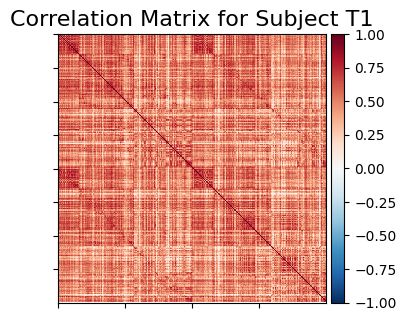

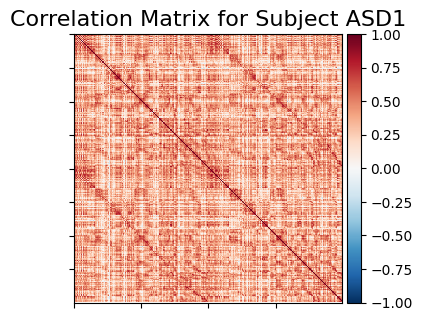

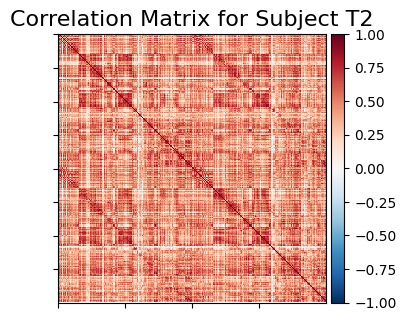

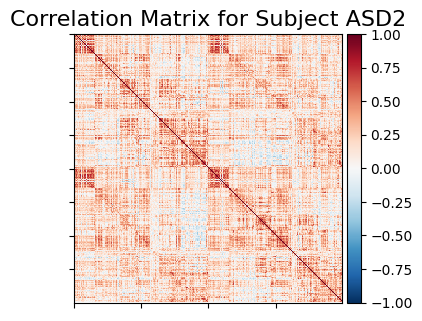

In [5]:
t1= all_correlation_matrices[0]
asd1= all_correlation_matrices[1]
t2= all_correlation_matrices[2]
asd2= all_correlation_matrices[3]
plotting.plot_matrix(t1, figure=(3, 3), colorbar=True, vmax=1, vmin=-1, title="Correlation Matrix for Subject T1")
plotting.plot_matrix(asd1, figure=(3, 3), colorbar=True, vmax=1, vmin=-1, title="Correlation Matrix for Subject ASD1")
plotting.plot_matrix(t2, figure=(3, 3), colorbar=True, vmax=1, vmin=-1, title="Correlation Matrix for Subject T2")
plotting.plot_matrix(asd2, figure=(3, 3), colorbar=True, vmax=1, vmin=-1, title="Correlation Matrix for Subject ASD2")
plotting.show() 

In [6]:
coords = plotting.find_parcellation_cut_coords(labels_img=atlas.maps) #Finding the coordinates of the parcels in the atlas using the find_parcellation_cut_coords function. The labels_img parameter specifies the atlas image to be used for finding the coordinates.
print(f"Coordinates of the parcels: {coords}")
distance_matrix = cdist(coords, coords, metric='euclidean') #Computing the distance matrix between the parcels using the cdist function from scipy.spatial.distance. The coords parameter specifies the coordinates of the parcels, and the metric parameter specifies the distance metric to be used (in this case, Euclidean distance).
print(f"Distance matrix shape: {distance_matrix.shape}")

Coordinates of the parcels: [[-32.1849711  -41.40462428 -21.06358382]
 [-30.06117647 -32.55058824 -18.04705882]
 [-35.36569579 -62.03236246 -17.05501618]
 ...
 [  4.10294118 -19.69852941  37.04411765]
 [  9.89285714 -52.60714286  35.13095238]
 [  7.25523013 -49.69874477  44.39330544]]
Distance matrix shape: (400, 400)


In [ ]:
matrices = [t1, asd1, t2, asd2]
weighted_long_range_graphs = []
long_range_mask = distance_matrix > 75.0 

for i, mat in enumerate(matrices):
    current_mat = mat.copy() 
    np.fill_diagonal(current_mat, 0)
     
    weighted_matrix = np.abs(current_mat)
    fc_long_range_weighted = weighted_matrix*long_range_mask
    
    weighted_long_range_graphs.append(fc_long_range_weighted)
    print(f"{weighted_long_range_graphs[i]}") 

[[0.         0.         0.         ... 0.         0.         0.5015206 ]
 [0.         0.         0.         ... 0.         0.         0.        ]
 [0.         0.         0.         ... 0.4743043  0.         0.37210956]
 ...
 [0.         0.         0.4743043  ... 0.         0.         0.        ]
 [0.         0.         0.         ... 0.         0.         0.        ]
 [0.5015206  0.         0.37210956 ... 0.         0.         0.        ]]
[[0.         0.         0.         ... 0.         0.         0.41812077]
 [0.         0.         0.         ... 0.         0.         0.        ]
 [0.         0.         0.         ... 0.4649648  0.         0.40415984]
 ...
 [0.         0.         0.4649648  ... 0.         0.         0.        ]
 [0.         0.         0.         ... 0.         0.         0.        ]
 [0.41812077 0.         0.40415984 ... 0.         0.         0.        ]]
[[0.         0.         0.         ... 0.         0.         0.40493777]
 [0.         0.         0.         ... 

In [9]:
subjects = ['T1', 'ASD1', 'T2', 'ASD2']
all_strength_scores = []

for i, mat in enumerate(weighted_long_range_graphs):
    
    # NetworkX, matristeki değerleri otomatik olarak 'weight' özelliği (edge attribute) olarak atar
    G = nx.from_numpy_array(mat)
    
    # 1. Degree Centrality (Kenar Sayma) YERİNE Node Strength (Bağlantı Gücü Toplamı)
    # G.degree() fonksiyonuna 'weight' argümanını vererek ağırlıklı dereceyi hesaplıyoruz
    strength_scores = dict(G.degree(weight='weight'))
    all_strength_scores.append(strength_scores)
    
    sorted_hubs = sorted(strength_scores.items(), key=lambda item: item[1], reverse=True) 
    
    print(f"Subject {subjects[i]} En Güçlü 5 Uzun Mesafeli Hub")
    for node, score in sorted_hubs[:5]:
        anatomik_isim = atlas.labels[node + 1] 
        print(f"Node {node} | İsim: {anatomik_isim} | Düğüm Gücü: {score:.3f}")
        
    print("\n") # Her denek arası boşluk bırak

Subject T1 En Güçlü 5 Uzun Mesafeli Hub
Node 170 | İsim: 7Networks_LH_Default_PFC_6 | Düğüm Gücü: 174.523
Node 134 | İsim: 7Networks_LH_Cont_PFCl_1 | Düğüm Gücü: 173.756
Node 342 | İsim: 7Networks_RH_Cont_PFCl_3 | Düğüm Gücü: 169.974
Node 136 | İsim: 7Networks_LH_Cont_PFCl_3 | Düğüm Gücü: 169.366
Node 368 | İsim: 7Networks_RH_Default_Temp_3 | Düğüm Gücü: 167.578


Subject ASD1 En Güçlü 5 Uzun Mesafeli Hub
Node 152 | İsim: 7Networks_LH_Default_Temp_5 | Düğüm Gücü: 141.490
Node 340 | İsim: 7Networks_RH_Cont_PFCl_1 | Düğüm Gücü: 139.523
Node 170 | İsim: 7Networks_LH_Default_PFC_6 | Düğüm Gücü: 138.776
Node 323 | İsim: 7Networks_RH_Limbic_OFC_6 | Düğüm Gücü: 138.111
Node 370 | İsim: 7Networks_RH_Default_Temp_5 | Düğüm Gücü: 137.247


Subject T2 En Güçlü 5 Uzun Mesafeli Hub
Node 137 | İsim: 7Networks_LH_Cont_PFCl_4 | Düğüm Gücü: 157.874
Node 136 | İsim: 7Networks_LH_Cont_PFCl_3 | Düğüm Gücü: 154.343
Node 379 | İsim: 7Networks_RH_Default_PFCdPFCm_2 | Düğüm Gücü: 153.437
Node 11 | İsim: 7Netw

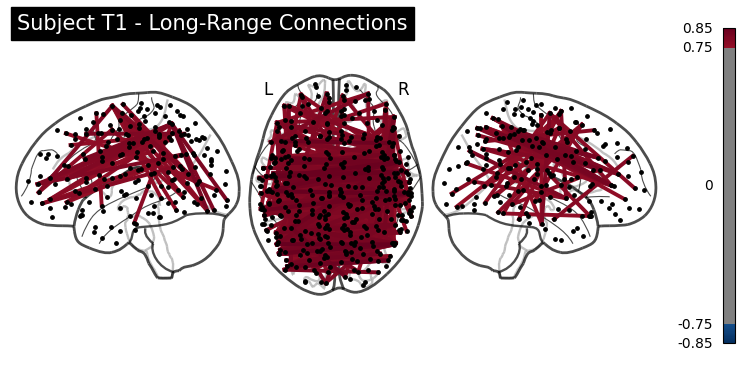

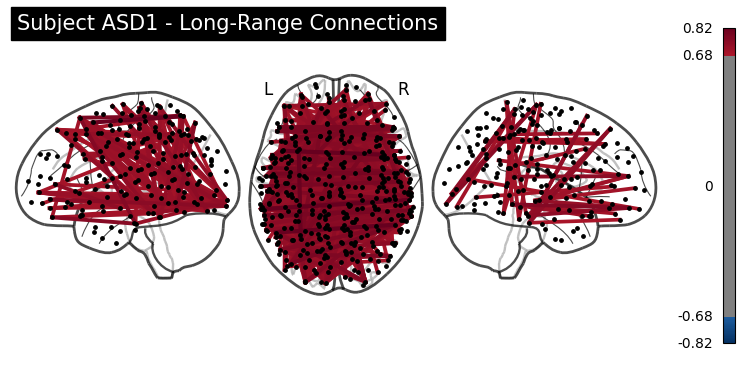

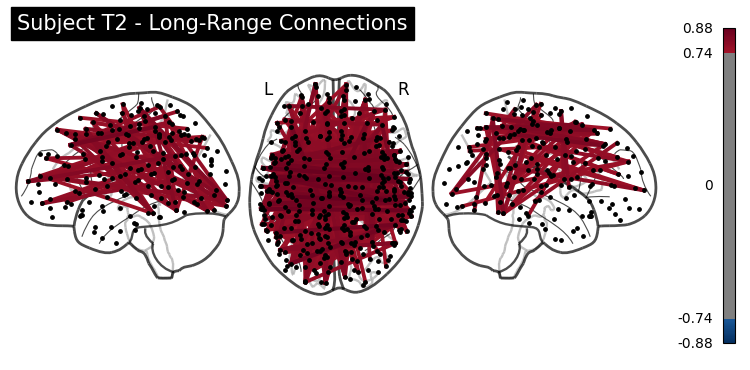

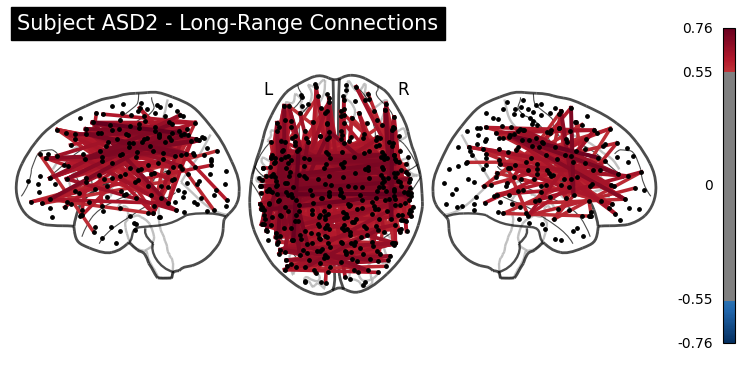

In [11]:
for i, mat in enumerate(weighted_long_range_graphs):
    np.fill_diagonal(mat, 0)
    
    display = plotting.plot_connectome(
        mat, 
        coords, 
        title=f"Subject {subjects[i]} - Long-Range Connections",
        node_size=6,           
        edge_threshold='99.5%', 
        node_color='black',    
        display_mode='lzr',
        colorbar=True)
    plotting.show() 

In [18]:
import numpy as np
import networkx as nx
from tqdm import tqdm

mat_observed = weighted_long_range_graphs[0]
G_observed = nx.from_numpy_array(mat_observed)

observed_metric = nx.average_clustering(G_observed, weight='weight')

num_permutations = 1000
null_metrics = []

non_zero_indices = np.nonzero(np.triu(mat_observed, k=1))
weights_to_shuffle = mat_observed[non_zero_indices]

for _ in tqdm(range(num_permutations)):
    
    shuffled_weights = np.random.permutation(weights_to_shuffle)
    mat_rand = np.zeros_like(mat_observed)
    mat_rand[non_zero_indices] = shuffled_weights
    mat_rand = mat_rand + mat_rand.T
    G_rand = nx.from_numpy_array(mat_rand)
    null_metrics.append(nx.average_clustering(G_rand, weight='weight'))

null_metrics = np.array(null_metrics)

p_value = np.mean(null_metrics >= observed_metric)

print(f"Obersved: {observed_metric:.4f}")
print(f"Null: {null_metrics.mean():.4f} ± {null_metrics.std():.4f}")
print(f"p-val: {p_value:.4f}")

100%|██████████| 1000/1000 [4:42:36<00:00, 16.96s/it] 

Obersved: 0.2782
Null: 0.2763 ± 0.0001
p-val: 0.0000
